In [8]:
import platform
import sys

import pandas as pd
import polars as pl
import psutil

print("=== Конфигурация окружения ===")
print(f"OS: {platform.system()} {platform.release()}")
print(f"Python: {sys.version.split()[0]}")
print(f"CPU cores: {psutil.cpu_count(logical=True)}")
print(
    f"RAM: {round(psutil.virtual_memory().total / (1024**3), 2)} GB"
)
print(f"pandas version: {pd.__version__}")
print(f"polars version: {pl.__version__}")

=== Конфигурация окружения ===
OS: Windows 11
Python: 3.12.14
CPU cores: 4
RAM: 7.8 GB
pandas version: 3.0.6
polars version: 1.44.2


In [9]:
import statistics
import time
from pathlib import Path

import pandas as pd
import polars as pl

# ---------------------------------------------------------
# Путь к оптимизированному Parquet-файлу из Шага 10
# ---------------------------------------------------------
PARQUET_PATH = Path("../data/interim/data_after_opt.parquet")

# ---------------------------------------------------------
# Подготовка справочников способов оплаты для операции Join
# ---------------------------------------------------------
# 1. Справочник для pandas
payment_lookup_pd = pd.DataFrame(
    {
        "payment_type": [1, 2, 3, 4],
        "payment_name": ["Credit card", "Cash", "No charge", "Dispute"],
    }
)
# Переводим в category для совпадения типов при объединении в pandas
payment_lookup_pd["payment_type"] = payment_lookup_pd["payment_type"].astype(
    "category"
)

# 2. Справочник для polars
payment_lookup_pl = pl.DataFrame(
    {
        "payment_type": [1, 2, 3, 4],
        "payment_name": ["Credit card", "Cash", "No charge", "Dispute"],
    }
)

# Загружаем базовые датафреймы заранее для проведения одиночных замеров
df_pd = pd.read_parquet(PARQUET_PATH)
df_pl = pl.read_parquet(PARQUET_PATH)

# Приводим тип payment_type в справочнике Polars к ТОЧНО ТАКОМУ ЖЕ типу, как в Parquet
payment_lookup_pl = payment_lookup_pl.with_columns(
    pl.col("payment_type").cast(df_pl["payment_type"].dtype)
)


# Функция для точного замера медианного времени (из 5 прогонов)
def measure_time(fn, runs=5):
    times = []
    for _ in range(runs):
        start = time.perf_counter()
        fn()
        times.append(time.perf_counter() - start)
    return statistics.median(times)


print("Запуск замеров производительности...")

# ---------------------------------------------------------
# 1. Чтение Parquet
# ---------------------------------------------------------
t_read_pd = measure_time(lambda: pd.read_parquet(PARQUET_PATH))
t_read_pl = measure_time(lambda: pl.read_parquet(PARQUET_PATH))

# ---------------------------------------------------------
# 2. Фильтрация (trip_distance > 2.0)
# ---------------------------------------------------------
t_filter_pd = measure_time(lambda: df_pd[df_pd["trip_distance"] > 2.0])
t_filter_pl = measure_time(
    lambda: df_pl.filter(pl.col("trip_distance") > 2.0)
)

filtered_pd = df_pd[df_pd["trip_distance"] > 2.0]
filtered_pl = df_pl.filter(pl.col("trip_distance") > 2.0)

# ---------------------------------------------------------
# 3. Группировка и агрегирование (медиана fare_amount по payment_type)
# ---------------------------------------------------------
t_group_pd = measure_time(
    lambda: filtered_pd.groupby("payment_type", observed=False)[
        "fare_amount"
    ].median()
)
t_group_pl = measure_time(
    lambda: filtered_pl.group_by("payment_type").agg(
        pl.col("fare_amount").median()
    )
)

grouped_pd = (
    filtered_pd.groupby("payment_type", observed=False)["fare_amount"]
    .median()
    .reset_index()
)
grouped_pl = filtered_pl.group_by("payment_type").agg(
    pl.col("fare_amount").median()
)

# ---------------------------------------------------------
# 4. Сортировка
# ---------------------------------------------------------
t_sort_pd = measure_time(
    lambda: grouped_pd.sort_values(by="fare_amount", ascending=False)
)
t_sort_pl = measure_time(
    lambda: grouped_pl.sort("fare_amount", descending=True)
)

sorted_pd = grouped_pd.sort_values(by="fare_amount", ascending=False)
sorted_pl = grouped_pl.sort("fare_amount", descending=True)

# ---------------------------------------------------------
# 5. Соединение таблиц (Join)
# ---------------------------------------------------------
t_join_pd = measure_time(
    lambda: pd.merge(sorted_pd, payment_lookup_pd, on="payment_type", how="left")
)
t_join_pl = measure_time(
    lambda: sorted_pl.join(payment_lookup_pl, on="payment_type", how="left")
)

# ---------------------------------------------------------
# 6. Цепочка операций (Eager Pandas vs Lazy Polars)
# ---------------------------------------------------------


def full_pipeline_pd():
    df = pd.read_parquet(PARQUET_PATH)
    res = (
        df[df["trip_distance"] > 2.0]
        .groupby("payment_type", observed=False)["fare_amount"]
        .median()
        .reset_index()
        .sort_values(by="fare_amount", ascending=False)
    )
    return pd.merge(res, payment_lookup_pd, on="payment_type", how="left")


def full_pipeline_pl_lazy():
    lookup_lazy = payment_lookup_pl.lazy()
    return (
        pl.scan_parquet(PARQUET_PATH)
        .filter(pl.col("trip_distance") > 2.0)
        .group_by("payment_type")
        .agg(pl.col("fare_amount").median())
        .sort("fare_amount", descending=True)
        .join(lookup_lazy, on="payment_type", how="left")
        .collect()
    )


t_pipe_pd = measure_time(full_pipeline_pd)
t_pipe_pl = measure_time(full_pipeline_pl_lazy)

# ---------------------------------------------------------
# Сборка и вывод Таблицы 8
# ---------------------------------------------------------
table8_raw = [
    ("Чтение Parquet", t_read_pd, t_read_pl),
    ("Фильтрация", t_filter_pd, t_filter_pl),
    ("Группировка и агрегирование", t_group_pd, t_group_pl),
    ("Сортировка", t_sort_pd, t_sort_pl),
    ("Соединение таблиц", t_join_pd, t_join_pl),
    ("Цепочка операций (ленивый режим)", t_pipe_pd, t_pipe_pl),
]

table8_data = []
for op_name, pd_t, pl_t in table8_raw:
    accel = pd_t / pl_t if pl_t > 0 else 0
    table8_data.append(
        {
            "Операция": op_name,
            "pandas, с": f"{pd_t:.4f}",
            "polars, с": f"{pl_t:.4f}",
            "Ускорение": f"{accel:.2f}x",
        }
    )

df_table8 = pd.DataFrame(table8_data)
print("\n=== Таблица 8 - Сравнение производительности pandas и polars ===")
print(df_table8.to_string(index=False))

Запуск замеров производительности...


C:\Users\cendv\AppData\Local\Temp\ipykernel_17344\148999698.py:41: DeprecationWarning: casting from Int64 to Categorical is deprecated.
Instead of `.cast(Categorical`, use `.cat.to(Categorical)`.
  payment_lookup_pl = payment_lookup_pl.with_columns(



=== Таблица 8 - Сравнение производительности pandas и polars ===
                        Операция pandas, с polars, с Ускорение
                  Чтение Parquet    0.0211    0.0296     0.71x
                      Фильтрация    0.0069    0.0012     5.84x
     Группировка и агрегирование    0.0028    0.0021     1.34x
                      Сортировка    0.0003    0.0001     3.22x
               Соединение таблиц    0.0056    0.0003    22.01x
Цепочка операций (ленивый режим)    0.0706    0.0153     4.62x


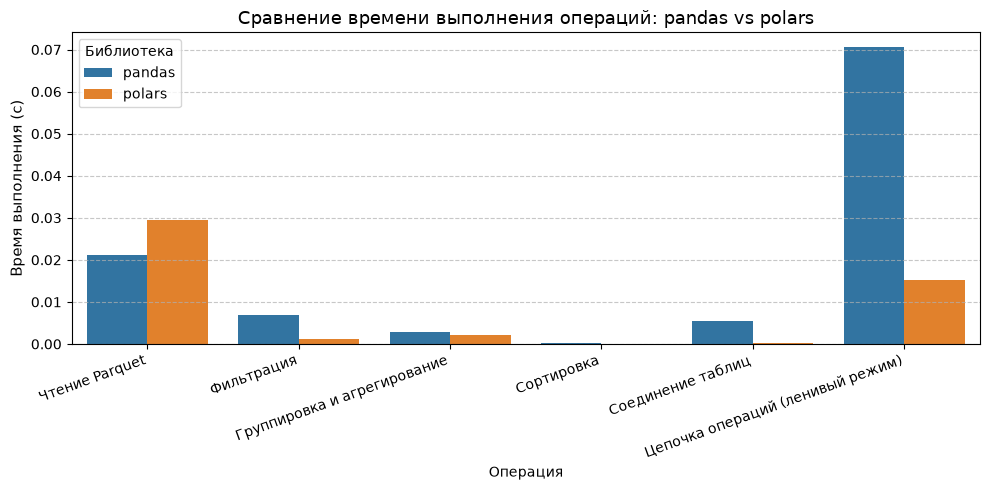

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Подготовка данных для визуализации
df_plot = pd.DataFrame(table8_raw, columns=["Операция", "pandas", "polars"])
df_plot_melted = df_plot.melt(
    id_vars="Операция",
    var_name="Библиотека",
    value_name="Время (секунды)",
)

plt.figure(figsize=(10, 5))
sns.barplot(
    data=df_plot_melted,
    x="Операция",
    y="Время (секунды)",
    hue="Библиотека",
    palette=["#1f77b4", "#ff7f0e"],
)

plt.title("Сравнение времени выполнения операций: pandas vs polars", fontsize=13)
plt.ylabel("Время выполнения (с)", fontsize=11)
plt.xlabel("Операция", fontsize=11)
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()